# Hype Pitch EDA: do thematic ETFs underperform after their theme peaks in public attention?

**The thesis.** Ben-David, Franzoni, Kim & Moussawi (*Journal of Finance* 2023), "Competition for Attention in the ETF
Space": specialized (thematic) ETFs are launched and bought when their theme is at peak attention, after their stocks
have already run up, and then underperform by about 6% a year. The mechanism is price-insensitive retail demand that
follows attention, not value. If that holds, a measure of public attention to a theme should predict its ETF's
*future underperformance* relative to the market.

**The attention measure.** Daily English-Wikipedia pageviews (human traffic only) of 1–3 pages per theme, chosen in
advance from the obvious names (`data/themes.csv`). Pageviews are a free, daily, public measure of what the public
reads about; for day *t* they are published early on day *t+1*.

**Hype signal.** S = log(mean views, last 28 days) − log(mean views over the prior 365 days). S = 0.69 means twice the
theme's normal attention. Measured at each month-end; returns start the next month.

**Questions (exploratory; no trading rule yet).**
1. Data: which ETFs, which pages, what coverage?
2. What do the attention series look like (weekly cycle, trends, bot spikes)?
3. Do the hype episodes the signal finds match known manias?
4. How many independent episodes are there (cross-theme correlation)?
5. Does attention line up with trading activity in the ETFs, and does it follow past returns (as the paper says)?
6. What happens to a theme's ETF after an attention spike (event study)?
7. Does attention predict next-month / next-quarter excess returns across themes, in 2016–2020 and in 2021–?
8. Does attention add anything beyond price momentum?

**Data.** `collect_wiki.py` (Wikimedia pageviews API, 2015-07 onward; each page's views plus the views of all ~1,700
titles that redirect to the theme pages, so that renamed articles keep a continuous series); `collect_prices.py` (Yahoo daily prices for
49 US-listed thematic ETFs plus SPY/QQQ/IWM). Theme return = equal-weight daily log return of the theme's ETFs
available that day; excess return = minus SPY.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SPLIT = pd.Timestamp("2021-01-01")
TH = pd.read_csv("data/themes.csv")
v = pd.read_csv("data/wiki_views.csv", parse_dates=["date"]); v["views"] = v[["desktop", "mobile_web", "mobile_app"]].sum(1)
V0 = v.pivot(index="date", columns="page", values="views")
RD = pd.read_csv("data/wiki_redirects.csv", parse_dates=["date"]).groupby(["date", "page"]).views.sum().unstack().reindex_like(V0).fillna(0)
V = V0 + RD                            # article + every title redirecting to it (keeps series continuous across renames)
p = pd.read_csv("data/prices.csv", parse_dates=["date"])
A = p.pivot(index="date", columns="ticker", values="adj_close"); DVOL = p.pivot(index="date", columns="ticker", values="close") * p.pivot(index="date", columns="ticker", values="volume")
START = {"MJ": "2018-01-01"}          # MJ was a Latin-America ETF until it converted to cannabis in late 2017
TV, TR, TD = {}, {}, {}
for _, r in TH.iterrows():
    pages = r.pages.split(";"); TV[r.theme] = V[pages].sum(1, min_count=len(pages))
    etfs = [e for e in r.etfs.split(";") if e in A]
    rr = np.log(A[etfs]).diff(); dv = DVOL[etfs].copy()
    for e in etfs:
        if e in START: rr.loc[:START[e], e] = np.nan; dv.loc[:START[e], e] = np.nan
    TR[r.theme] = rr.mean(1); TD[r.theme] = dv.sum(1, min_count=1)
TV, TR, TD = pd.DataFrame(TV), pd.DataFrame(TR), pd.DataFrame(TD)
spy = np.log(A.SPY).diff()
missing = sorted({e for s in TH.etfs for e in s.split(";")} - set(A.columns))
first = p.groupby("ticker").date.min().dt.date
TH["ETFs with data (first date)"] = TH.etfs.map(lambda s: ", ".join(f"{e} ({first[e]})" for e in s.split(";") if e in first))
print(TH[["theme", "pages", "ETFs with data (first date)"]].to_string(index=False))
print("\nETFs with no Yahoo data (closed):", missing)

                theme                                                               pages                                              ETFs with data (first date)
             cannabis Cannabis in the United States;Legality of cannabis;Medical cannabis MJ (2015-12-03), MSOS (2020-09-02), YOLO (2019-04-18), CNBS (2019-07-23)
              uranium                         Uranium;Nuclear power;Small modular reactor                    URA (2015-01-02), URNM (2019-12-04), NLR (2015-01-02)
              lithium                                         Lithium;Lithium-ion battery                                      LIT (2015-01-02), BATT (2018-06-06)
    electric_vehicles                                       Electric vehicle;Electric car                  DRIV (2018-04-17), IDRV (2019-04-18), KARS (2018-01-25)
                solar                                           Solar power;Photovoltaics                                                         TAN (2015-01-02)
         clean_energy 

**Interpretation.** 26 themes, 46 ETFs with prices, 51 Wikipedia pages. Three closed ETFs (HDRO, HJEN, IRBO) have no
Yahoo history, a small survivorship gap. IRBO's theme (AI) is still covered by other ETFs, but hydrogen loses both of
its ETFs, so 25 themes have returns. Many ETFs start in 2018–2021,
so the cross-section grows from about 15 themes in 2016 to 26 by 2022. Yahoo has no usable shares-outstanding history
for most of these ETFs, so ETF *flows* cannot be measured directly; dollar volume is used as the activity proxy.

## 2. What the attention series look like
**What this does.** Weekly views (log scale) for a selection of themes; the day-of-week profile and the mobile share of
views over time (pooled across pages); a rename check (largest jump in a page's 30-day median views, with and without
redirect views added); and a bot check: days whose views exceed 10× the page's centred 15-day median.

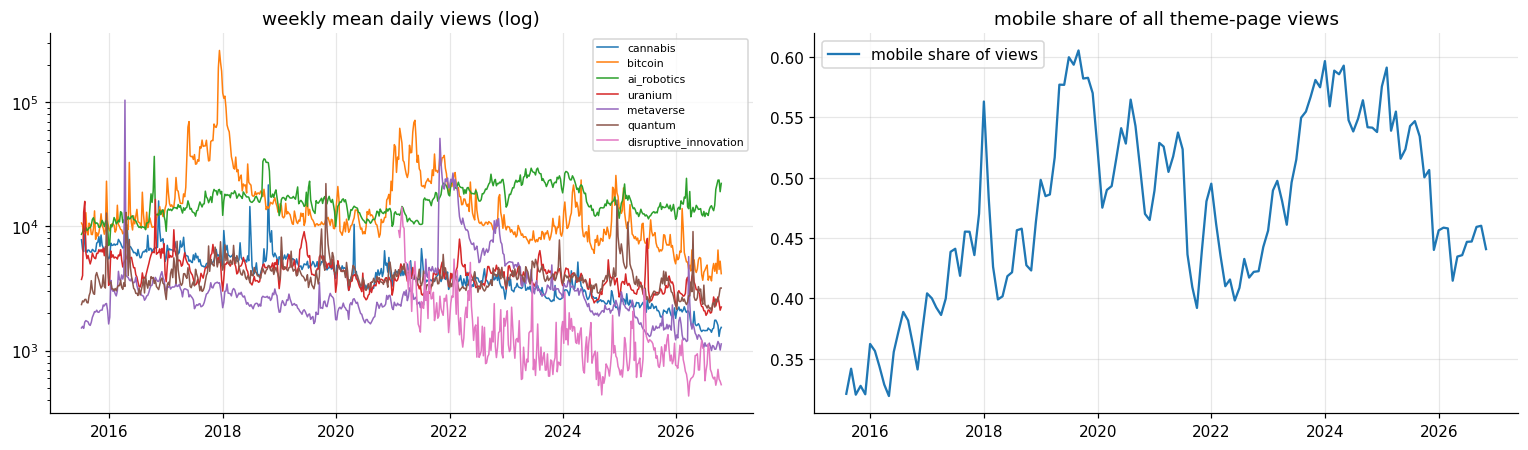

day-of-week log deviation from weekly mean: {'Mon': 0.074, 'Tue': 0.105, 'Wed': 0.102, 'Thu': 0.084, 'Fri': -0.007, 'Sat': -0.207, 'Sun': -0.151}
largest 30-day level jump (x), pages above 4x:
                      article only  with redirects
page                                              
Blockchain                    60.0             1.6
Robinhood Markets             50.0             4.0
Rare-earth element            45.8             4.9
Esports                       15.9             1.5
Non-fungible token            15.0            14.0
Metaverse                      9.2             9.2
Financial technology           4.7             1.9


days with views > 10x the 15-day median, by page (nonzero):
page
Cloud computing          4
Cathie Wood              2
Robinhood Markets        2
SpaceX                   2
Virtual reality          2
Blockchain               1
Computer security        1
Cryptocurrency           1
Electric car             1
Gold as an investment    1
Non-fungible token       1
Nuclear power            1
Private spaceflight      1
Quantum computing        1
Ransomware               1
Video game industry      1


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for t in ["cannabis", "bitcoin", "ai_robotics", "uranium", "metaverse", "quantum", "disruptive_innovation"]:
    ax[0].plot(TV[t].resample("W").mean(), label=t, lw=1)
ax[0].set_yscale("log"); ax[0].set_title("weekly mean daily views (log)"); ax[0].legend(fontsize=7)
tot = v.groupby("date")[["desktop", "mobile_web", "mobile_app"]].sum()
ax[1].plot((tot.mobile_web + tot.mobile_app).div(tot.sum(1)).resample("ME").mean(), label="mobile share of views")
ax[1].set_title("mobile share of all theme-page views"); ax[1].legend()
plt.tight_layout(); plt.show()
dow = (np.log(V).sub(np.log(V).rolling(7, center=True).mean())).groupby(V.index.dayofweek).mean().mean(1)
print("day-of-week log deviation from weekly mean:", dict(zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.round(3))))
def jump(X):
    m = X.rolling(30, min_periods=20).median(); return (m.shift(-30) / m).max()
J = pd.DataFrame({"article only": jump(V0), "with redirects": jump(V)}); print("largest 30-day level jump (x), pages above 4x:")
print(J[J.max(1) > 4].round(1).sort_values("article only", ascending=False).to_string())
spk = (V / V.rolling(15, center=True, min_periods=8).median() > 10).sum()
print("days with views > 10x the 15-day median, by page (nonzero):"); print(spk[spk > 0].sort_values(ascending=False).to_string())

**Interpretation.**
- **Renamed articles must be stitched.** Four pages jump 16–60× in a month on the article title alone (Blockchain
  2017, Rare-earth element 2017, Esports 2018, Robinhood Markets 2021): these are page moves, not attention. With
  redirect views added the jumps fall to 1.5–5×. The remaining large jumps are real events: NFTs (Feb 2021) and the
  metaverse (Facebook's rename to Meta, Oct 2021). All analysis below uses article + redirect views.
- **Weekly cycle:** theme pages are read about 10% more Monday–Thursday and 15–20% less at weekends. The 28-day window
  in the signal averages it out.
- **Mobile share drifts up over time,** a slow trend that the one-year baseline absorbs.
- **Bot-like one-day spikes are rare** (at most four days per page in eleven years) and a 28-day average dampens them.

## 3. The hype signal and its biggest episodes
**What this does.** Computes S daily, lists for each theme the month with the highest S and its value, and plots S for
a few themes. If the signal works as a "hype" measure, the peaks should line up with known manias.

                      peak month  peak S  x normal
blockchain               2021-03    2.29       9.8
fintech                  2021-01    2.10       8.2
space                    2020-05    2.10       8.1
metaverse                2021-10    1.89       6.6
cybersecurity            2017-05    1.84       6.3
rare_earths              2019-05    1.71       5.5
bitcoin                  2017-12    1.68       5.3
social_media             2025-01    1.01       2.7
quantum                  2024-12    0.88       2.4
silver                   2026-01    0.85       2.3
disruptive_innovation    2025-06    0.82       2.3
cloud                    2021-08    0.78       2.2
gold                     2024-04    0.66       1.9
cannabis                 2018-10    0.64       1.9
lithium                  2023-02    0.61       1.8
genomics                 2020-10    0.60       1.8
ai_robotics              2016-10    0.59       1.8
uranium                  2025-06    0.51       1.7
semiconductors           2021-0

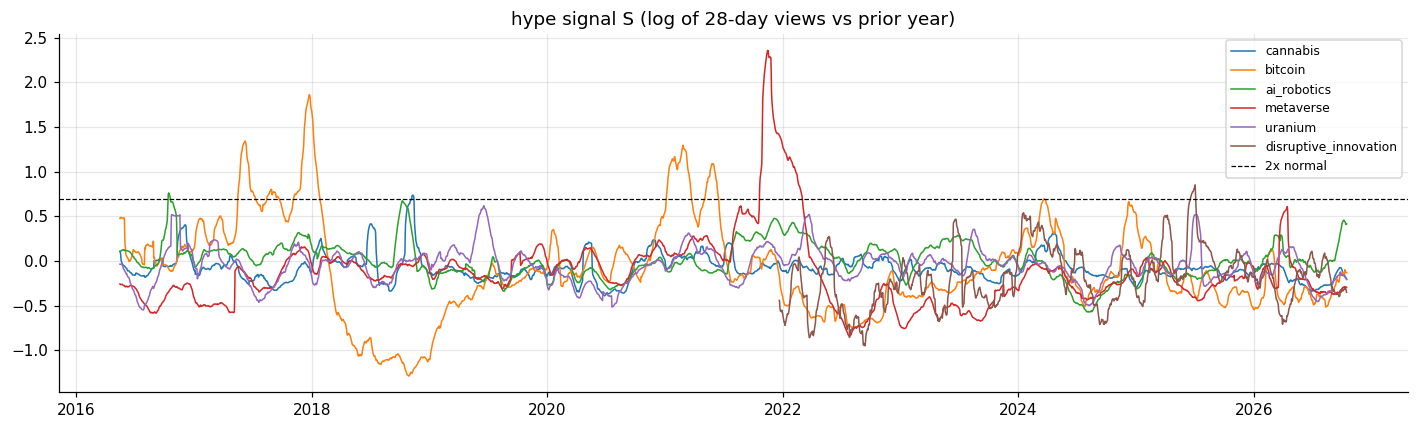

In [3]:
def signal(w_recent=28, w_base=365):
    a = np.log(TV.rolling(w_recent, min_periods=int(w_recent * 0.7)).mean())
    b = np.log(TV.shift(w_recent).rolling(w_base, min_periods=int(w_base * 0.8)).mean())
    return a - b
Sd = signal(); S = Sd.resample("ME").last()
peaks = pd.DataFrame({"peak month": S.idxmax().dt.strftime("%Y-%m"), "peak S": S.max().round(2), "x normal": np.exp(S.max()).round(1)}).sort_values("peak S", ascending=False)
print(peaks.to_string())
fig, ax = plt.subplots(figsize=(13, 4))
for t in ["cannabis", "bitcoin", "ai_robotics", "metaverse", "uranium", "disruptive_innovation"]:
    ax.plot(Sd[t], label=t, lw=1)
ax.axhline(np.log(2), c="k", ls="--", lw=0.8, label="2x normal"); ax.set_title("hype signal S (log of 28-day views vs prior year)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Most top readings are recognisable manias:** blockchain / NFTs (Mar 2021), fintech (Jan 2021: Robinhood and
  GameStop), space (May 2020: first SpaceX crewed launch), the metaverse (Oct 2021), bitcoin (Dec 2017), rare earths
  (May 2019: China export-ban threats), quantum computing (Dec 2024).
- **Some misses.** AI's largest reading is Oct 2016, not 2023: AI pages were already heavily read, so the 2023 boom is
  a smaller *relative* jump (1.6–1.8× the prior year). Ark / Cathie Wood's 2021 mania is missed because both pages were
  created in 2021 and the signal needs a year of history. Cannabis peaks at only 1.9× (Oct 2018, Canadian legalisation).
- Only seven themes ever exceed 3× normal. The signal is dominated by a few crypto / fintech / space episodes.

## 4. How many independent episodes?
**What this does.** Correlation of monthly S changes across themes, and the share of variance explained by the first
principal component. If themes move together, the effective sample is smaller than the theme count.

In [4]:
dS = S.diff().dropna(how="all")
c = dS.corr()
off = c.values[np.triu_indices_from(c, 1)]
print(f"mean pairwise correlation of monthly S changes: {np.nanmean(off):.2f}; share of pairs above 0.5: {(off > 0.5).mean():.2f}")
z = dS.dropna(axis=1, thresh=len(dS) * 0.6).fillna(0); ev = np.linalg.eigvalsh(np.cov(((z - z.mean()) / z.std()).T))[::-1]
print(f"first principal component explains {ev[0] / ev.sum():.0%} of the variance of S changes")
pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("most correlated theme pairs:"); print(pairs.head(8).round(2).to_string())

mean pairwise correlation of monthly S changes: 0.20; share of pairs above 0.5: 0.07
first principal component explains 28% of the variance of S changes
most correlated theme pairs:
solar         clean_energy    0.78
clean_energy  copper          0.74
              hydrogen        0.74
lithium       copper          0.71
solar         copper          0.69
              hydrogen        0.68
hydrogen      copper          0.66
lithium       solar           0.66


**Interpretation.** Attention changes are mostly independent across themes (mean pairwise correlation 0.20; the first
principal component explains 28%). The one tight cluster is energy transition: solar, clean energy, hydrogen, lithium
and copper (pairwise 0.66–0.78). Counting that cluster as one, the effective cross-section is about 20 themes, though
spike events concentrate in a few of them (space and rare earths alone give 7 of the 19 events below).

## 5. Attention, trading activity and past returns
**What this does.** (a) Same-month and lead/lag correlation between S and abnormal ETF dollar volume (log of 28-day
volume vs prior year), pooled across themes. (b) Correlation between S and the theme's past 3-month and next 1-month
excess returns. The paper predicts attention rises *after* strong returns and comes with heavier trading.

In [5]:
DVS = (np.log(TD.rolling(28, min_periods=20).mean()) - np.log(TD.shift(28).rolling(365, min_periods=290).mean())).resample("ME").last()
me = TR.resample("ME").sum(min_count=5); ex = me.sub(spy.resample("ME").sum(), axis=0)
past3 = ex.rolling(3).sum()
rows = []
for lag in [-2, -1, 0, 1, 2]:
    a = pd.DataFrame({"S": S.stack(), "x": DVS.shift(-lag).stack()}).dropna()
    rows.append({"volume lead (+) / lag (−), months": lag, "corr(S, abnormal dollar volume)": a.S.corr(a.x)})
print(pd.DataFrame(rows).round(3).to_string(index=False))
pan = pd.DataFrame({"S": S.stack(), "past 3m excess": past3.stack(), "next 1m excess": ex.shift(-1).stack()}).dropna()
print("\npooled correlations:"); print(pan.corr().round(3).to_string())

 volume lead (+) / lag (−), months  corr(S, abnormal dollar volume)
                                -2                            0.161
                                -1                            0.207
                                 0                            0.269
                                 1                            0.248
                                 2                            0.199

pooled correlations:
                    S  past 3m excess  next 1m excess
S               1.000           0.212           0.018
past 3m excess  0.212           1.000           0.083
next 1m excess  0.018           0.083           1.000


**Interpretation.**
- **Attention and trading go together.** S correlates 0.27 with abnormal ETF dollar volume in the same month, falling
  to 0.16–0.25 one or two months either side. Hype months are heavy-trading months.
- **Attention follows returns:** S correlates 0.21 with the past 3-month excess return, as the paper describes.
- **But the next-month correlation is about zero (0.02).** Nothing points to the predicted underperformance.

## 6. Event study: what happens after an attention spike?
**What this does.** Events: the first month-end at which a theme's S exceeds log 2 (twice normal attention), with no
event for that theme in the prior 12 months. Mean cumulative excess return (theme ETFs minus SPY) from 6 months before
to 12 months after the event month. The thesis predicts a run-up before and a decline after.

19 events: cloud 2021-07, cybersecurity 2017-05, disruptive_innovation 2025-06, fintech 2021-01, blockchain 2021-02, bitcoin 2017-05, bitcoin 2021-01, metaverse 2021-10, space 2018-02, space 2020-05, space 2024-10, space 2026-06, social_media 2024-03, quantum 2019-10, quantum 2024-12, rare_earths 2019-05, rare_earths 2023-01, rare_earths 2025-02, silver 2025-10

mean excess return months -5..0 (run-up): +19.9% (n 17)
months +1..+1: +1.7%  median +2.3%  t +0.69  (n 18; negative in 39%)
months +1..+3: +2.3%  median -3.4%  t +0.41  (n 18; negative in 56%)
months +1..+6: +1.7%  median -2.4%  t +0.21  (n 17; negative in 59%)
months +1..+12: -8.0%  median +0.7%  t -0.71  (n 17; negative in 47%)


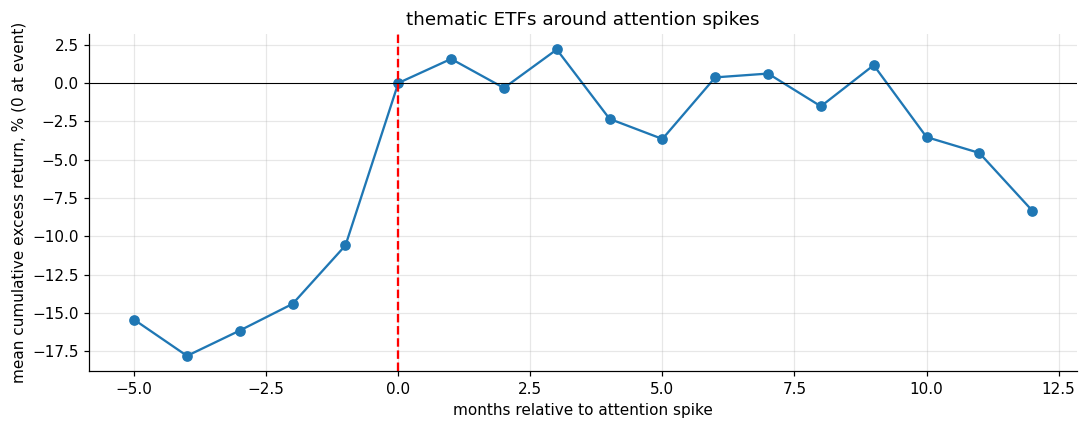

In [6]:
ev = []
for t in S:
    s = S[t].dropna(); last = None
    for d, x in s.items():
        if x > np.log(2) and (last is None or (d - last).days > 365):
            ev.append((t, d)); last = d
print(len(ev), "events:", ", ".join(f"{t} {d:%Y-%m}" for t, d in ev))
paths = []
for t, d in ev:
    e = ex[t]; i = e.index.get_loc(d)
    path = {k: e.iloc[i + k] if 0 <= i + k < len(e) else np.nan for k in range(-5, 13)}
    paths.append(pd.Series(path, name=f"{t} {d:%Y-%m}"))
P = pd.DataFrame(paths)
car_pre = P[[k for k in range(-5, 1)]].sum(1, min_count=6); car_post = {H: P[[k for k in range(1, H + 1)]].sum(1, min_count=H) for H in [1, 3, 6, 12]}
print(f"\nmean excess return months -5..0 (run-up): {car_pre.mean() * 100:+.1f}% (n {car_pre.notna().sum()})")
for H, c in car_post.items():
    c = c.dropna(); print(f"months +1..+{H}: {c.mean() * 100:+.1f}%  median {c.median() * 100:+.1f}%  t {c.mean() / c.std() * np.sqrt(len(c)):+.2f}  (n {len(c)}; negative in {(c < 0).mean():.0%})")
cum = P.fillna(0).cumsum(1).sub(P.fillna(0).cumsum(1)[0], axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cum.columns, cum.mean() * 100, marker="o"); ax.axvline(0, c="r", ls="--"); ax.axhline(0, c="k", lw=0.7)
ax.set_xlabel("months relative to attention spike"); ax.set_ylabel("mean cumulative excess return, % (0 at event)"); ax.set_title("thematic ETFs around attention spikes")
plt.tight_layout(); plt.show()

**Interpretation.**
- **The run-up is there:** themes beat SPY by about 20% on average in the six months up to an attention spike. Hype
  arrives after the returns.
- **There is no reliable decline after.** The mean excess return is +1.7% in the next month, +2.3% over 3 months and
  +1.7% over 6, all with t below 0.7. The 12-month mean is −8.0% (t −0.7), but the median is +0.7% and fewer than half
  of events are negative. The busts are almost all **one episode**: the 2021 spikes (metaverse −58%, fintech −56%,
  blockchain −51%, bitcoin −44%, cloud −39% over the next 12 months) that collapsed together in 2022, plus rare earths
  in 2019 and 2023. Next to them are spikes that kept running: bitcoin May 2017 (+70%), rare earths 2025 (+78%), space
  2024 (+49%).
- 19 events in eleven years, clustered in 2017 and 2020–21, is too few to separate a real reversal from noise.

## 7. Cross-section: does attention predict excess returns?
**What this does.** Each month, rank themes by S. Report the next 1-, 3- and 6-month excess return of the top tercile
minus the bottom tercile, and the Fama-MacBeth slope on standardised S, for 2016–2020 and 2021– (Newey-West t).
The thesis predicts negative numbers.

In [7]:
def sort_test(Sx, H):
    fwd = sum(ex.shift(-k) for k in range(1, H + 1))
    z = pd.DataFrame({"S": Sx.stack(), "fwd": fwd.stack()}).dropna(); out = []
    for per, m in [("2016–2020", z.index.get_level_values(0) < SPLIT), ("2021–", z.index.get_level_values(0) >= SPLIT)]:
        g = z[m].groupby(level=0)
        tb = g.apply(lambda q: q.fwd[q.S >= q.S.quantile(2 / 3)].mean() - q.fwd[q.S <= q.S.quantile(1 / 3)].mean() if len(q) >= 8 else np.nan).dropna()
        sl = g.apply(lambda q: np.polyfit((q.S - q.S.mean()) / q.S.std(), q.fwd, 1)[0] if len(q) >= 8 else np.nan).dropna()
        t1 = sm.OLS(tb, np.ones(len(tb))).fit(cov_type="HAC", cov_kwds={"maxlags": H}).tvalues.iloc[0]
        t2 = sm.OLS(sl, np.ones(len(sl))).fit(cov_type="HAC", cov_kwds={"maxlags": H}).tvalues.iloc[0]
        out.append({"horizon (months)": H, "era": per, "months": len(tb), "top−bottom tercile %": tb.mean() * 100, "t": t1, "FM slope %/1sd": sl.mean() * 100, "t FM": t2})
    return out
R = pd.DataFrame([r for H in [1, 3, 6] for r in sort_test(S, H)])
print(R.round(2).to_string(index=False))

 horizon (months)       era  months  top−bottom tercile %    t  FM slope %/1sd  t FM
                1 2016–2020      56                  1.39 1.80            0.78  1.31
                1     2021–      69                  0.67 1.16            0.53  1.77
                3 2016–2020      56                  4.00 2.30            2.51  1.49
                3     2021–      67                  0.60 0.49            0.43  0.74
                6 2016–2020      56                  4.45 1.10            3.01  0.91
                6     2021–      64                  0.09 0.04            0.26  0.26


**Interpretation.** The sign is the *opposite* of the thesis: high-attention themes do slightly *better* afterwards.
Top-minus-bottom tercile: +1.4%/month in 2016–2020 (t 1.8) and +0.7% since 2021 (t 1.2); at 3 months +4.0% (t 2.3)
in 2016–2020 but +0.6% (t 0.5) since. Nothing is significant in both eras, and nothing is negative.

## 8. Is attention anything more than momentum?
**What this does.** Fama-MacBeth regressions of next-month theme excess return on standardised S and standardised past
3-month excess return together, by era. If attention only proxies for recent returns, its coefficient should vanish.

In [8]:
z = pd.DataFrame({"S": S.stack(), "mom": past3.stack(), "fwd": ex.shift(-1).stack()}).dropna()
for per, m in [("2016–2020", z.index.get_level_values(0) < SPLIT), ("2021–", z.index.get_level_values(0) >= SPLIT)]:
    co = []
    for d, q in z[m].groupby(level=0):
        if len(q) < 8: continue
        X = sm.add_constant(pd.DataFrame({"S": (q.S - q.S.mean()) / q.S.std(), "mom": (q.mom - q.mom.mean()) / q.mom.std()}))
        co.append(sm.OLS(q.fwd, X).fit().params)
    co = pd.DataFrame(co)
    ts = {k: sm.OLS(co[k], np.ones(len(co))).fit(cov_type="HAC", cov_kwds={"maxlags": 2}).tvalues.iloc[0] for k in ["S", "mom"]}
    print(f"{per}: attention {co.S.mean() * 100:+.2f}%/1sd (t {ts['S']:+.2f}) | 3m momentum {co.mom.mean() * 100:+.2f}%/1sd (t {ts['mom']:+.2f}) | months {len(co)}")

2016–2020: attention +0.42%/1sd (t +0.97) | 3m momentum +1.07%/1sd (t +2.19) | months 56
2021–: attention +0.41%/1sd (t +1.56) | 3m momentum +0.32%/1sd (t +1.07) | months 69


**Interpretation.** With past 3-month returns in the same regression, attention's coefficient is +0.4%/month per
standard deviation in both eras (t 1.0 and 1.6), not significant. In 2016–2020 theme momentum was the significant
variable (t 2.2); since 2021 neither is. The weak positive tilt in §7 is mostly theme momentum.

## 9. Takeaways

| question | answer |
|---|---|
| Does the signal measure hype? | Mostly. Peaks match known episodes (NFTs/blockchain 2021, fintech/GameStop 2021, metaverse 2021, bitcoin 2017, space 2020). It co-moves with abnormal ETF trading (corr 0.27). It misses AI 2023 (already high base) and Ark 2021 (pages too new). Article renames must be stitched with redirect views. |
| Does hype follow returns (paper)? | Yes. Themes beat SPY by about 20% in the 6 months before an attention spike; S correlates 0.21 with past 3-month returns. |
| Does hype predict underperformance? | No. High- minus low-attention themes earn +0.7 to +1.4%/month next month (t 1.2–1.8) and nothing negative at 3 or 6 months in either era. After spikes: +1.7% (1m), +2.3% (3m), −8.0% (12m, t −0.7, median +0.7%). |
| Anything beyond momentum? | No. Controlling for 3-month returns, attention's coefficient is t 1.0 / 1.6. |
| Sample size | About 20 effectively independent themes; 19 spike events in 11 years. The 12-month busts are essentially one episode (2021 spikes that collapsed in 2022). |

**Verdict: the signal is not strong enough.** Wikipedia attention is a good *descriptive* hype measure, but it does not
predict thematic-ETF underperformance at tradable horizons in either era. The paper's underperformance is measured over
years after an ETF's launch; at that horizon this sample has a handful of independent episodes, too few for in-sample
and out-of-sample t ≥ 2.